In [2]:
import pandas as pd
X_train = pd.read_csv("../data/processed/X_train_processed.csv")
X_test = pd.read_csv("../data/processed/X_test_processed.csv")

y_train = pd.read_csv(
    "../data/processed/y_train.csv"
).squeeze()

y_test = pd.read_csv(
    "../data/processed/y_test.csv"
).squeeze()

In [3]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [4]:
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    max_features="sqrt",
    min_samples_leaf=5,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42
)

In [5]:
final_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 

In [6]:
y_pred = final_model.predict(X_test)

In [7]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [8]:
y_proba = final_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_proba
)

In [9]:
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.7558552164655784
Precision: 0.5265017667844523
Recall: 0.7967914438502673
F1: 0.6340425531914894
ROC-AUC: 0.8423803249890206


In [10]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[767 268]
 [ 76 298]]


In [11]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1035
           1       0.53      0.80      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



# Test Different Thresholds

In [12]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_proba >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.round(4)

,Threshold,Precision,Recall,F1
0,0.10,0.3345,0.9920,0.5003
1,0.15,0.3553,0.9786,0.5214
2,0.20,0.3806,0.9545,0.5442
3,0.25,0.4082,0.9278,0.5670
4,0.30,0.4311,0.9037,0.5838
5,0.35,0.4447,0.8717,0.5890
6,0.40,0.4826,0.8529,0.6164
7,0.45,0.5066,0.8262,0.6280
8,0.50,0.5265,0.7968,0.6340
9,0.55,0.5440,0.7273,0.6224


In [13]:
best_threshold_row = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

best_threshold_row

Threshold    0.500000
Precision    0.526502
Recall       0.796791
F1           0.634043
Name: 8, dtype: float64

In [14]:
best_threshold = best_threshold_row["Threshold"]

print("Selected Threshold:", best_threshold)
print("Precision:", best_threshold_row["Precision"])
print("Recall:", best_threshold_row["Recall"])
print("F1:", best_threshold_row["F1"])

Selected Threshold: 0.5000000000000001
Precision: 0.5265017667844523
Recall: 0.7967914438502673
F1: 0.6340425531914894


# Final Evaluation

In [15]:
final_threshold = 0.50

In [16]:
y_proba_final = final_model.predict_proba(X_test)[:, 1]

y_pred_final = (
    y_proba_final >= final_threshold
).astype(int)

In [17]:
final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)
final_roc_auc = roc_auc_score(y_test, y_proba_final)

In [18]:
print("Final Model Evaluation")
print("----------------------")
print("Threshold:", final_threshold)
print("Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1:", final_f1)
print("ROC-AUC:", final_roc_auc)

Final Model Evaluation
----------------------
Threshold: 0.5
Accuracy: 0.7558552164655784
Precision: 0.5265017667844523
Recall: 0.7967914438502673
F1: 0.6340425531914894
ROC-AUC: 0.8423803249890206


In [19]:
final_cm = confusion_matrix(
    y_test,
    y_pred_final
)

print("Confusion Matrix:")
print(final_cm)

Confusion Matrix:
[[767 268]
 [ 76 298]]


In [20]:
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.82      1035
       Churn       0.53      0.80      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [21]:
final_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "Threshold": [final_threshold],
    "Accuracy": [final_accuracy],
    "Precision": [final_precision],
    "Recall": [final_recall],
    "F1": [final_f1],
    "ROC-AUC": [final_roc_auc]
})

final_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.5,0.7559,0.5265,0.7968,0.634,0.8424


In [22]:
final_results.round(4).to_csv(
    "../reports/final_model_results.csv",
    index=False
)

In [23]:
import joblib

In [24]:
joblib.dump(
    final_model,
    "../models/final_model.pkl"
)

['../models/final_model.pkl']

In [25]:
import joblib

preprocessor = joblib.load(
    "../models/preprocessor.pkl"
)

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [27]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

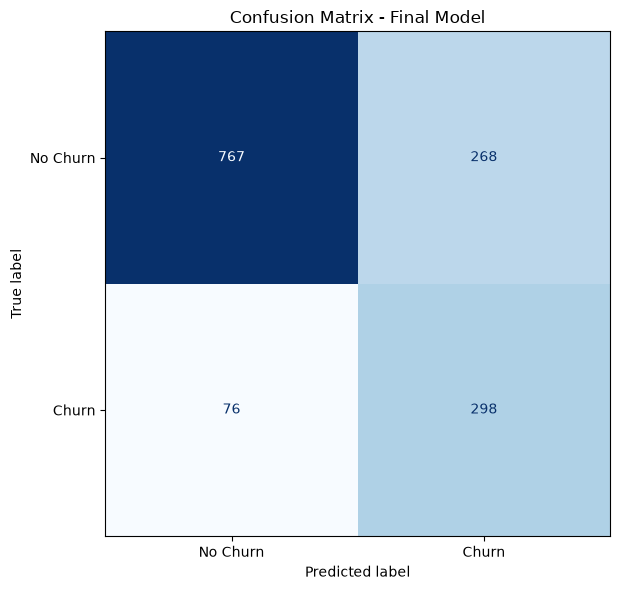

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Confusion Matrix - Final Model")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

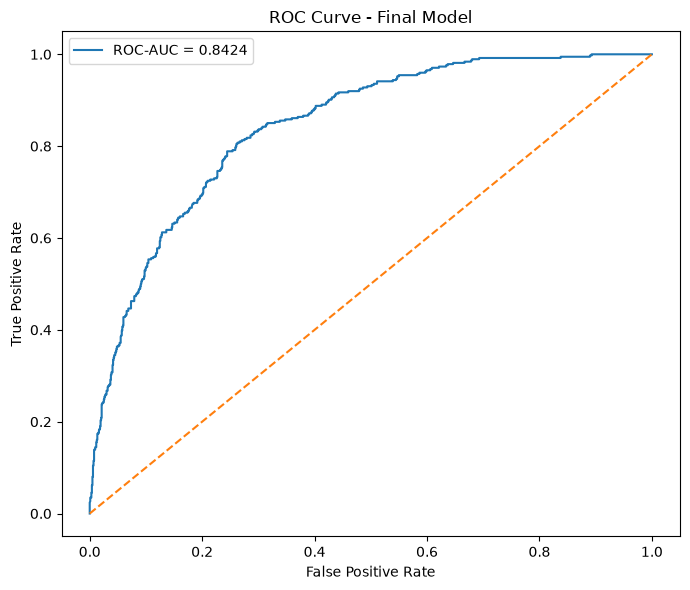

In [29]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get prediction probabilities
y_score = final_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# Calculate ROC-AUC
auc_score = roc_auc_score(y_test, y_score)

# Plot
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc_score:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve - Final Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

# Save figure
plt.savefig(
    "../reports/figures/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

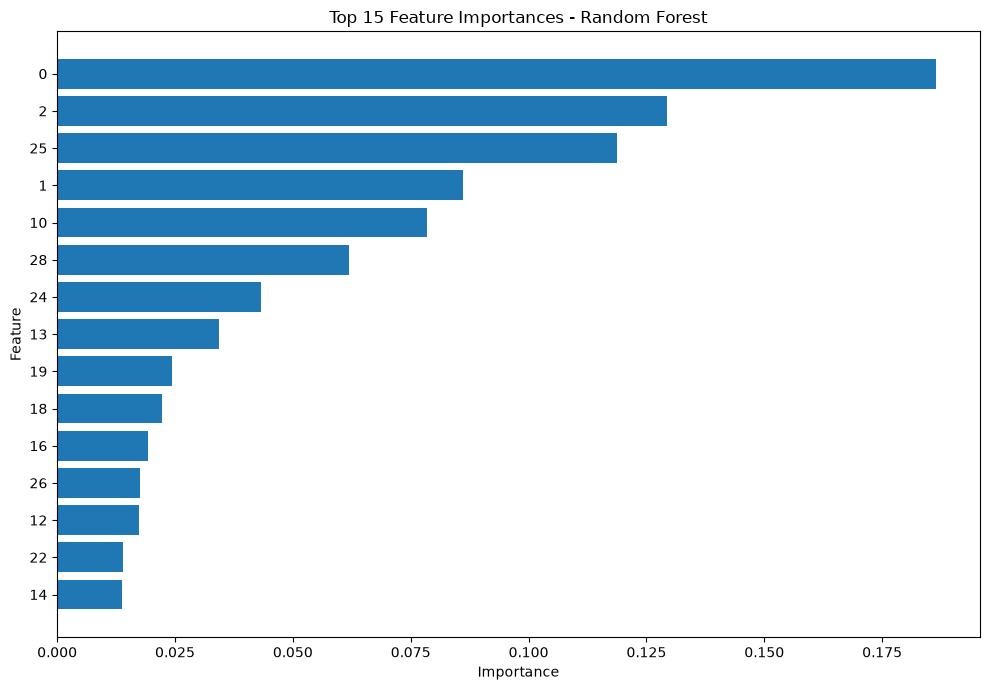

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Show top 15 features
top_features = feature_importance.head(15)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

# Save figure
plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()